# 04 — SAM/Vicon validation

Main local working notebook. Reuses `src.comparison_engine` for metrics and `src.plotting` for visualization. **Already-aligned CSVs with embedded Vicon** are legacy exploratory comparisons, not independent verification of synchronization.

In [1]:
import sys
print(sys.executable)

import numpy as np
print("NumPy:", np.__version__)

/Users/thomasjohnson/markerless/markerless_sam/.venv/bin/python
NumPy: 2.2.6


In [2]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display
ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir() and (ROOT.parent / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise FileNotFoundError("Run Jupyter from the repository or notebooks/ folder")
sys.path.insert(0, str(ROOT))
DATA = ROOT / "lunge_sam_out"
RESULTS = ROOT / "results"
print(ROOT, DATA.exists())

/Users/thomasjohnson/markerless/markerless_sam True


In [3]:
from src.comparison_engine import compare_angles
from src.plotting import plot_joint_overlays, plot_joint_errors, plot_camera_comparison
files = sorted(DATA.glob("*_joint_angles.csv"))
print(f"Found {len(files)} joint-angle CSV files")
for i, f in enumerate(files):
    print(i, f.name)

Found 21 joint-angle CSV files
0 s10_lunge_cam0_joint_angles.csv
1 s10_lunge_cam1_joint_angles.csv
2 s10_lunge_cam2_joint_angles.csv
3 s11_lunge_cam0_joint_angles.csv
4 s11_lunge_cam1_joint_angles.csv
5 s11_lunge_cam2_joint_angles.csv
6 s1_lunge_cam0_joint_angles.csv
7 s1_lunge_cam1_joint_angles.csv
8 s1_lunge_cam2_joint_angles.csv
9 s2_lunge_cam0_joint_angles.csv
10 s2_lunge_cam1_joint_angles.csv
11 s2_lunge_cam2_joint_angles.csv
12 s6_lunge_cam0_joint_angles.csv
13 s6_lunge_cam1_joint_angles.csv
14 s6_lunge_cam2_joint_angles.csv
15 s8_lunge_cam0_joint_angles.csv
16 s8_lunge_cam1_joint_angles.csv
17 s8_lunge_cam2_joint_angles.csv
18 s9_lunge_cam0_joint_angles.csv
19 s9_lunge_cam1_joint_angles.csv
20 s9_lunge_cam2_joint_angles.csv


In [4]:
SELECTED = 20
if files:
    csv_path = files[SELECTED]
    df = pd.read_csv(csv_path)
    display(df.head())
    print("Columns:", list(df.columns))
else:
    df = None
    print("Export/download pre-aligned joint angle CSV files into lunge_sam_out/")

,time_ms_aligned,vicon_ankle_flex,vicon_knee_flex,vicon_hip_flex,r_ankle_flex_euler,r_knee_flex_euler,r_hip_flex_euler,r_ankle_flex_geo,r_knee_flex_geo,r_hip_flex_geo
0,-1170.000000,NaN,NaN,NaN,84.282877,7.485972,-26.861265,76.164476,19.632880,6.520314
1,-1086.655076,NaN,NaN,NaN,82.732707,12.146654,-25.060857,73.909542,20.746477,7.770811
2,-1003.310153,NaN,NaN,NaN,81.646889,15.321477,-23.761005,72.392443,21.397769,8.569303
3,-919.965229,NaN,NaN,NaN,80.954749,17.210419,-22.900549,71.486106,21.629842,8.981837
4,-836.620306,NaN,NaN,NaN,80.585279,18.018484,-22.416766,71.063455,21.485781,9.074455


Columns: ['time_ms_aligned', 'vicon_ankle_flex', 'vicon_knee_flex', 'vicon_hip_flex', 'r_ankle_flex_euler', 'r_knee_flex_euler', 'r_hip_flex_euler', 'r_ankle_flex_geo', 'r_knee_flex_geo', 'r_hip_flex_geo']


In [5]:
# Validation 
if df is not None:
    import re
    match = re.match(r"(s[0-9]+)_lunge_(cam[0-9]+)_joint_angles[.]csv", csv_path.name, re.I)
    subject, camera = (match.group(1).upper(), match.group(2)) if match else ("unknown", "unknown")
    out_dir = RESULTS / subject / "lunge_01" / camera
    if "time_ms_aligned" not in df or not any(col.startswith("vicon_") for col in df):
        raise ValueError("Expected pre-aligned CSV with embedded Vicon. For raw inputs use independent sync JSON and Vicon CSV.")
    metrics = compare_angles(csv_path, out_dir, subject=subject, trial="lunge_01", camera=camera, allow_legacy_embedded_reference=True, plot=False)
    display(metrics)

,subject,trial,camera,side,joint,method,reference_origin,sync_method,sync_shift_ms,n_samples,...,sam_baseline_deg,rmse_neutral_deg,rmse_neutral_same_overlap_deg,rmse_neutral_shifted_deg,rmse_improvement_pct,diagnostic_shift_ms,calibration_window_ms,n_shift_overlap,calibration_status,shift_status
0,S9,lunge_01,cam2,right,hip,geo,embedded_preinterpolated_vicon_unverified,prealigned_upstream,None,129,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,not_requested,not_requested
1,S9,lunge_01,cam2,right,hip,euler,embedded_preinterpolated_vicon_unverified,prealigned_upstream,None,129,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,not_requested,not_requested
2,S9,lunge_01,cam2,right,knee,geo,embedded_preinterpolated_vicon_unverified,prealigned_upstream,None,129,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,not_requested,not_requested
3,S9,lunge_01,cam2,right,knee,euler,embedded_preinterpolated_vicon_unverified,prealigned_upstream,None,129,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,not_requested,not_requested
4,S9,lunge_01,cam2,right,ankle,geo,embedded_preinterpolated_vicon_unverified,prealigned_upstream,None,129,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,not_requested,not_requested
5,S9,lunge_01,cam2,right,ankle,euler,embedded_preinterpolated_vicon_unverified,prealigned_upstream,None,129,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,not_requested,not_requested


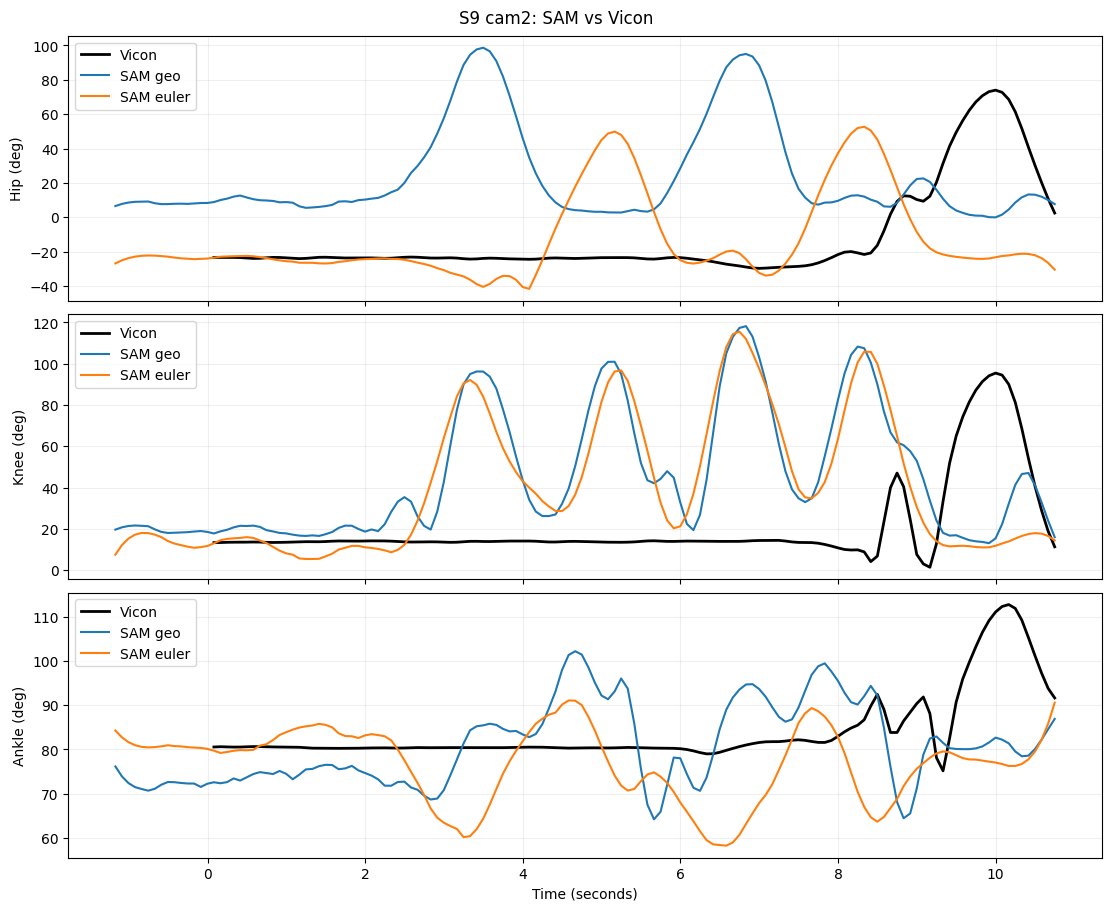

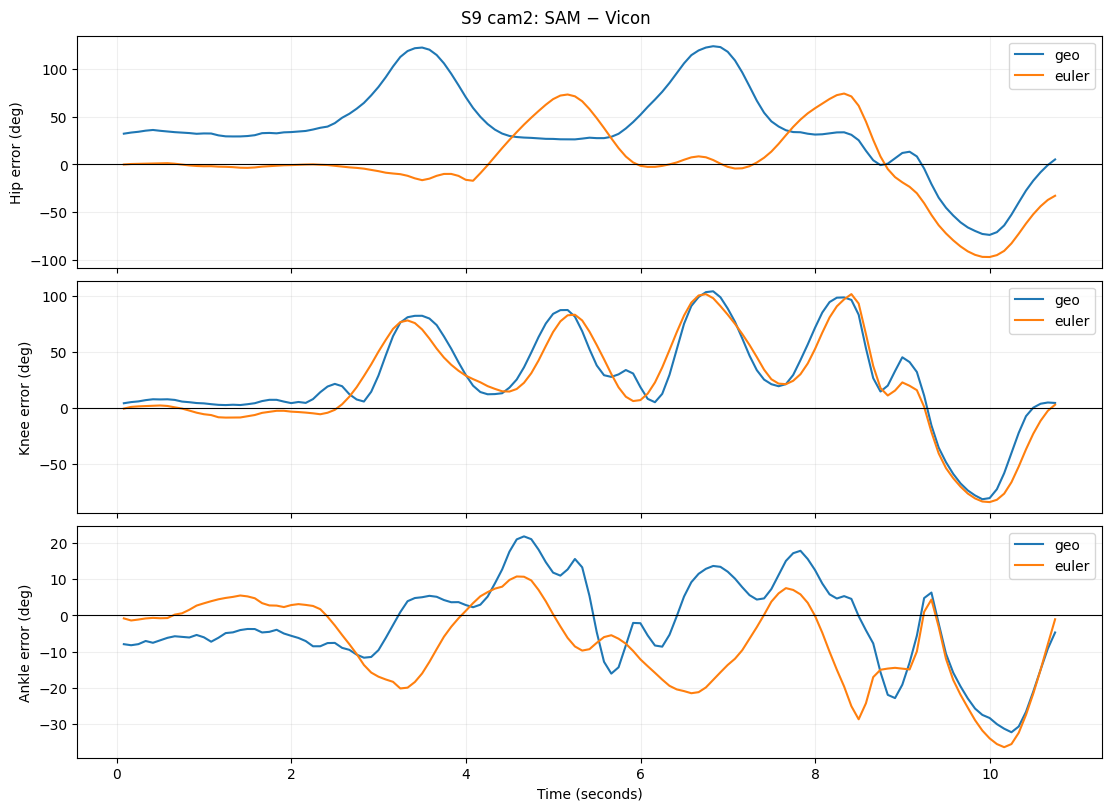

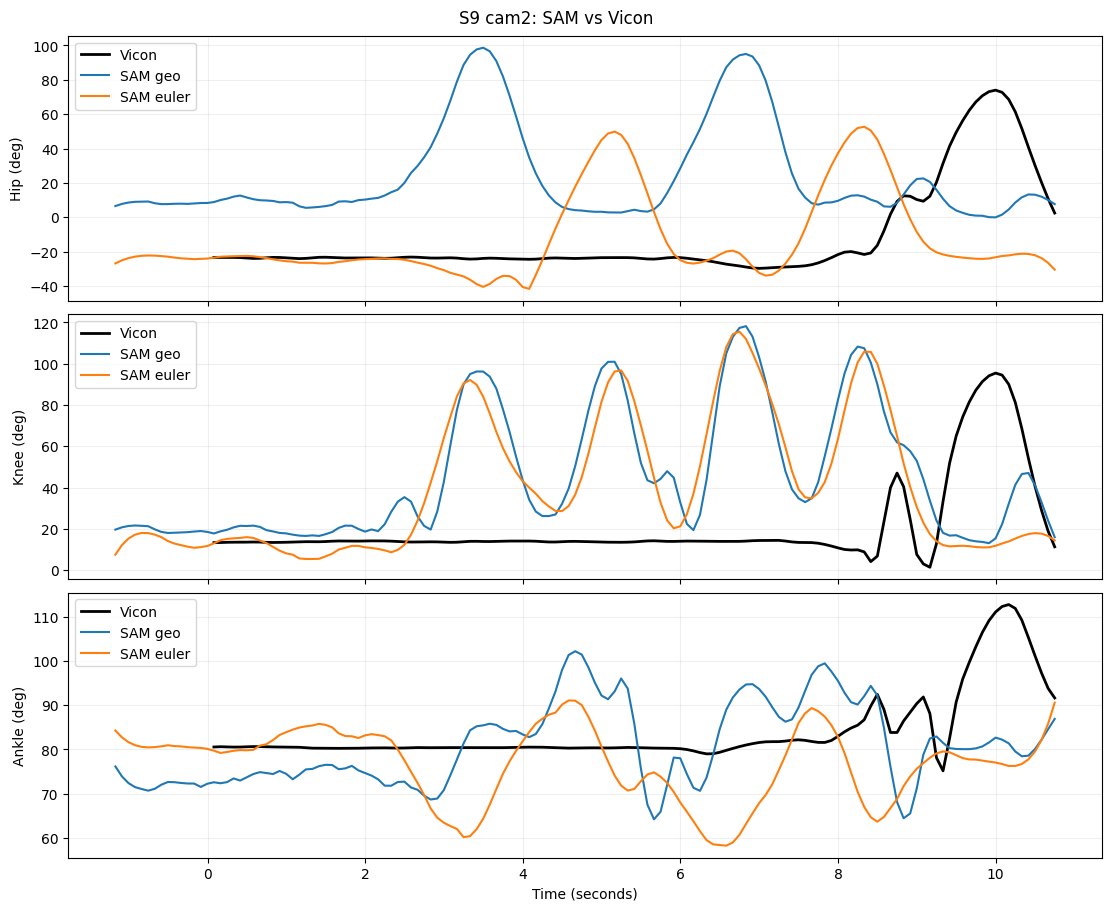

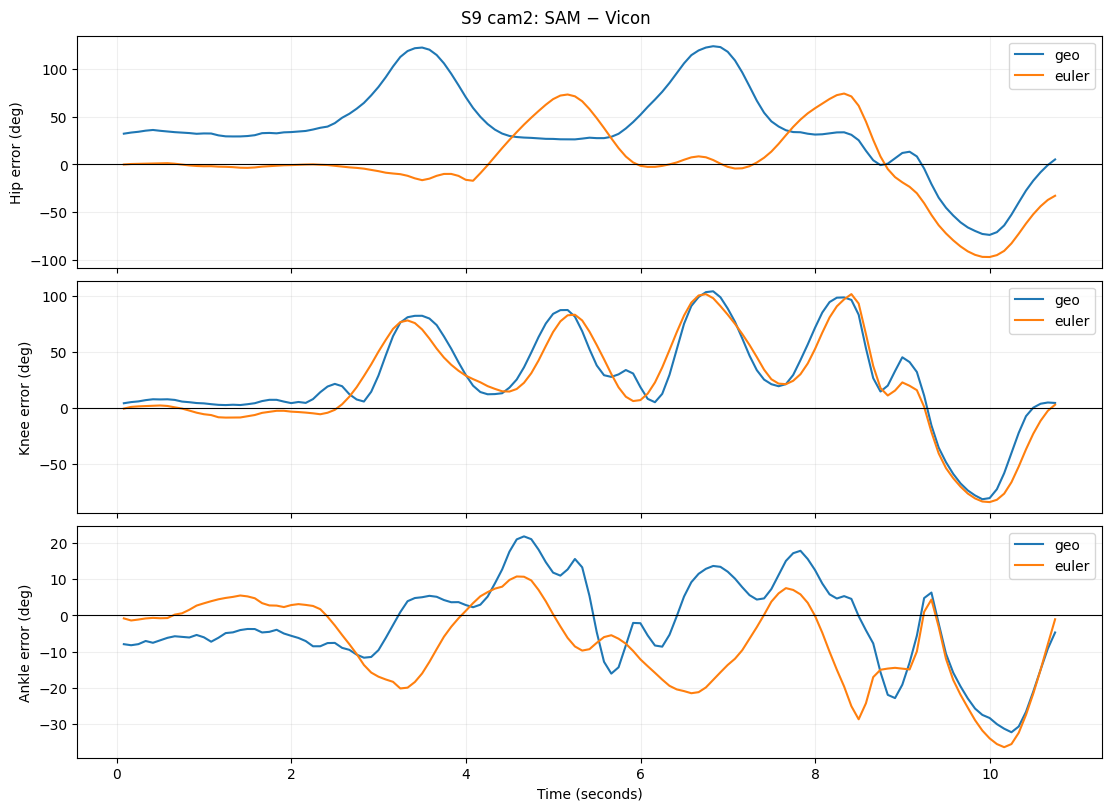

In [6]:
if df is not None:
    display(plot_joint_overlays(df, title=f"{subject} {camera}: SAM vs Vicon"))
    display(plot_joint_errors(df, title=f"{subject} {camera}: SAM − Vicon"))

In [ ]:
# Plot vicon only for comparison


TypeError: plot_camera_comparison() got an unexpected keyword argument 'title'

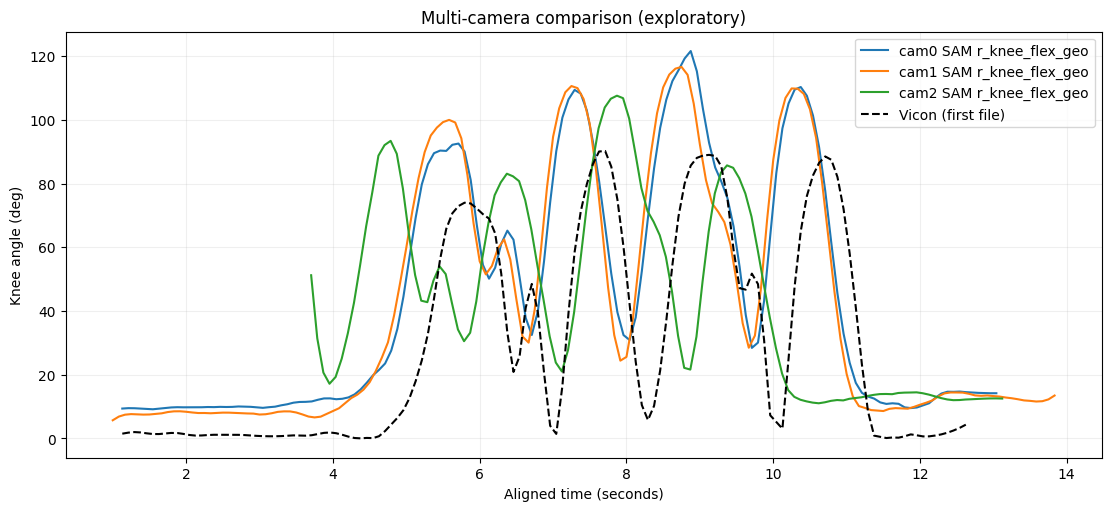

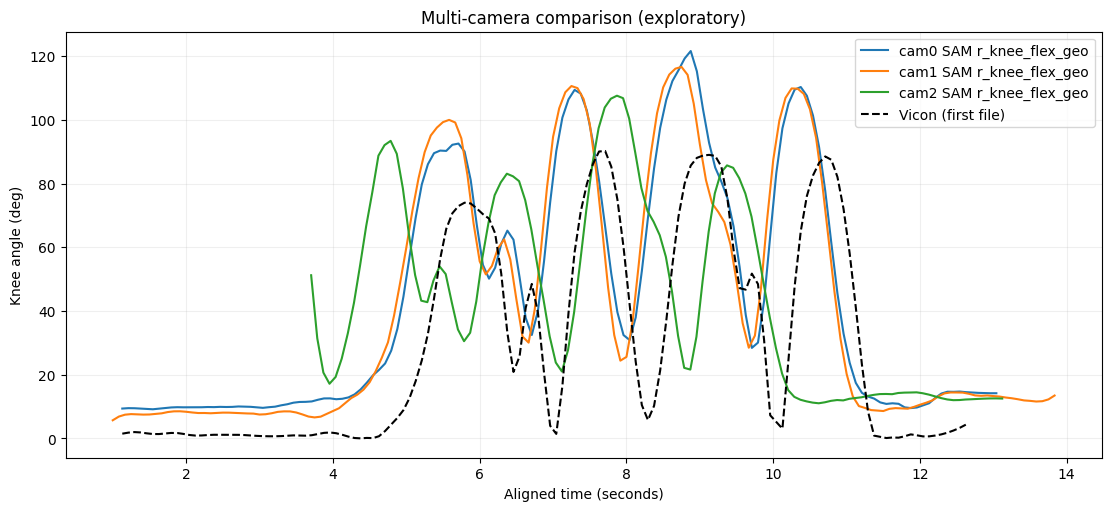

In [7]:
if len(files) >= 2:
    first_subject = files[0].name.split("_")[0]
    same_subject = [f for f in files if f.name.startswith(first_subject + "_")]
    if len(same_subject) >= 2:
        camera_frames = {p.name.split("_")[2]: pd.read_csv(p) for p in same_subject}
        display(plot_camera_comparison(camera_frames, joint="knee", method="geo"))

### Diagnose existing CSV's

,joint,method,vicon_baseline_deg,sam_baseline_deg,baseline_offset_deg,vicon_rom_deg,sam_rom_deg,rom_difference_deg,rmse_raw_deg,rmse_neutral_deg,diagnostic_lag_ms
0,hip,geo,-23.42,9.97,-33.39,103.68,98.68,-5.00,58.92,45.91,6417.56
1,hip,euler,-23.42,-23.08,-0.34,103.68,94.30,-9.38,39.22,39.22,4750.66
2,knee,geo,13.49,19.45,-5.96,94.09,105.17,11.07,49.63,46.67,3083.76
3,knee,euler,13.49,14.43,-0.94,94.09,110.16,16.07,49.11,48.70,3167.11
4,ankle,geo,80.57,74.08,6.49,37.58,38.00,0.42,12.46,12.90,5250.73
5,ankle,euler,80.57,79.89,0.69,37.58,32.82,-4.76,13.91,13.54,5667.45


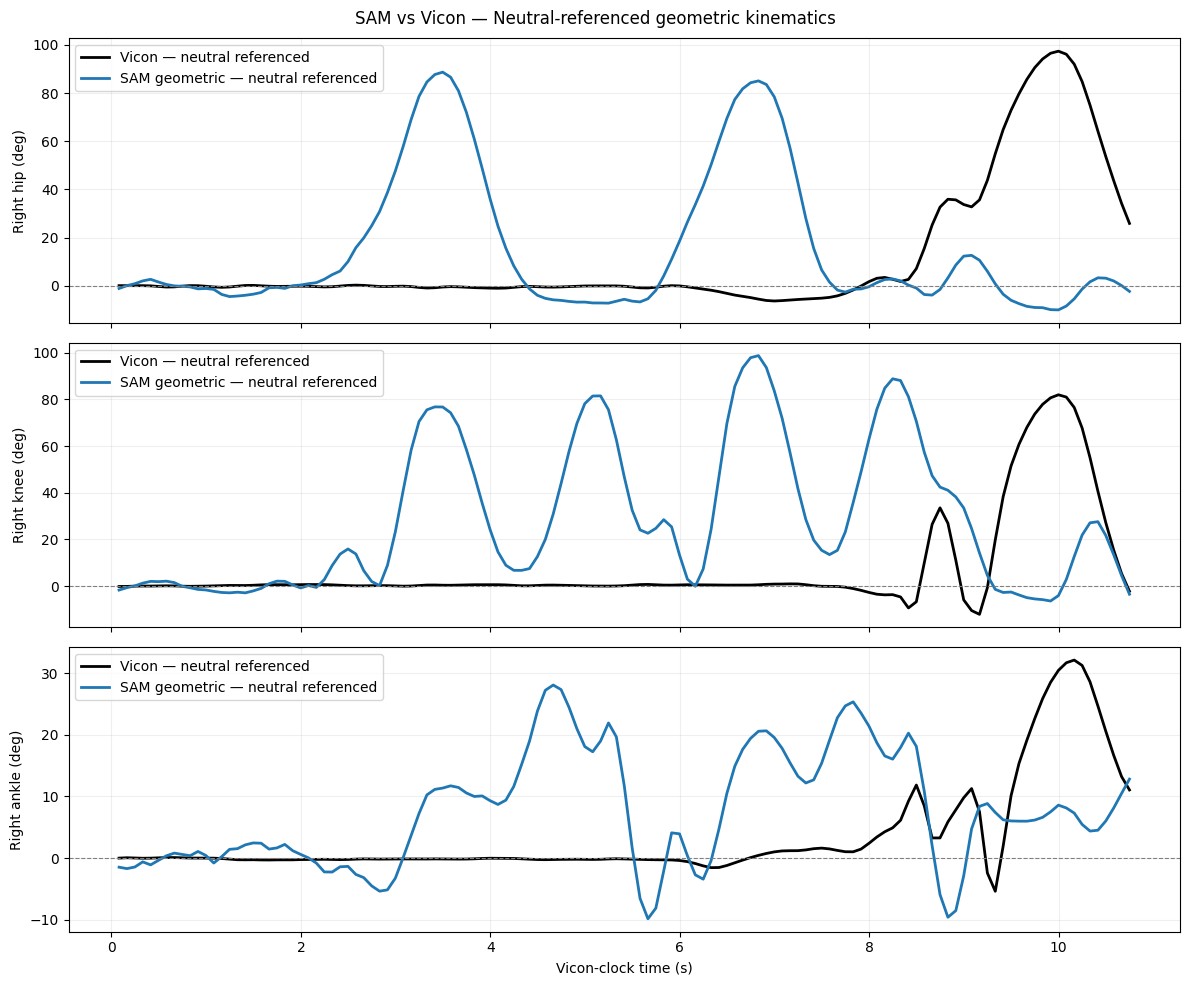

In [13]:

import matplotlib.pyplot as plt
from scipy.signal import correlate, correlation_lags

def diagnose_joint(
    df,
    joint="knee",
    method="geo",
    static_window_ms=1000,
    max_lag_ms=8000
):
    t = df["time_ms_aligned"].to_numpy(dtype=float)
    v = df[f"vicon_{joint}_flex"].to_numpy(dtype=float)
    s = df[f"r_{joint}_flex_{method}"].to_numpy(dtype=float)

    valid = np.isfinite(t) & np.isfinite(v) & np.isfinite(s)
    t, v, s = t[valid], v[valid], s[valid]

    if len(t) < 5 or np.any(np.diff(t) <= 0):
        raise ValueError("Insufficient valid, increasing timestamps")

    # ---------------------------------------------------
    # 1. Baseline / neutral reference
    # ---------------------------------------------------
    static = t <= t[0] + static_window_ms

    baseline_v = np.median(v[static])
    baseline_s = np.median(s[static])

    v_neutral = v - baseline_v
    s_neutral = s - baseline_s

    # ---------------------------------------------------
    # 2. Diagnostic temporal lag
    # ---------------------------------------------------
    dt = np.median(np.diff(t))

    grid = np.arange(t[0], t[-1], dt)

    vg = np.interp(grid, t, v_neutral)
    sg = np.interp(grid, t, s_neutral)

    a = vg - np.mean(vg)
    b = sg - np.mean(sg)

    corr = correlate(a, b, mode="full")
    lags = correlation_lags(len(a), len(b), mode="full")

    allowed = np.abs(lags * dt) <= max_lag_ms

    best_lag = (
        lags[allowed][np.argmax(corr[allowed])] * dt
    )

    # ---------------------------------------------------
    # 3. Metrics
    # ---------------------------------------------------
    rmse_raw = np.sqrt(np.mean((s - v) ** 2))

    rmse_neutral = np.sqrt(
        np.mean((s_neutral - v_neutral) ** 2)
    )

    result = {
        "joint": joint,
        "method": method,
        "vicon_baseline_deg": baseline_v,
        "sam_baseline_deg": baseline_s,
        "baseline_offset_deg": baseline_v - baseline_s,
        "vicon_rom_deg": np.ptp(v),
        "sam_rom_deg": np.ptp(s),
        "rom_difference_deg": np.ptp(s) - np.ptp(v),
        "rmse_raw_deg": rmse_raw,
        "rmse_neutral_deg": rmse_neutral,
        "diagnostic_lag_ms": best_lag,
    }

    return result, (t, v_neutral, s_neutral)


# ---------------------------------------------------
# 4. Diagnose all joints and methods
# ---------------------------------------------------
results = []
curves = {}

for joint in ("hip", "knee", "ankle"):
    for method in ("geo", "euler"):

        sam_col = f"r_{joint}_flex_{method}"
        vicon_col = f"vicon_{joint}_flex"

        if sam_col in df.columns and vicon_col in df.columns:
            result, curve = diagnose_joint(
                df,
                joint=joint,
                method=method,
                static_window_ms=1000
            )

            results.append(result)
            curves[(joint, method)] = curve

diagnostics = pd.DataFrame(results)

display(diagnostics.round(2))


# ---------------------------------------------------
# 5. Plot neutral-referenced geometric angles
# ---------------------------------------------------
fig, axes = plt.subplots(
    3, 1, figsize=(12, 10), sharex=True
)

for ax, joint in zip(axes, ("hip", "knee", "ankle")):

    if (joint, "geo") not in curves:
        continue

    t, v, s = curves[(joint, "geo")]

    ax.plot(
        t / 1000,
        v,
        label="Vicon — neutral referenced",
        color="black",
        linewidth=2
    )

    ax.plot(
        t / 1000,
        s,
        label="SAM geometric — neutral referenced",
        linewidth=2
    )

    ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)

    ax.set_ylabel(f"Right {joint} (deg)")
    ax.grid(alpha=0.2)
    ax.legend()

axes[-1].set_xlabel("Vicon-clock time (s)")

fig.suptitle(
    "SAM vs Vicon — Neutral-referenced geometric kinematics"
)

plt.tight_layout()
plt.show()

Diagnostic lag (knee, geometric): 416.7 ms


/var/folders/90/zl66g5qj47l1drgbk3nfzk_40000gn/T/ipykernel_4574/2944919708.py:16: RuntimeWarning: All-NaN slice encountered
  v = v - np.nanmedian(v[static])


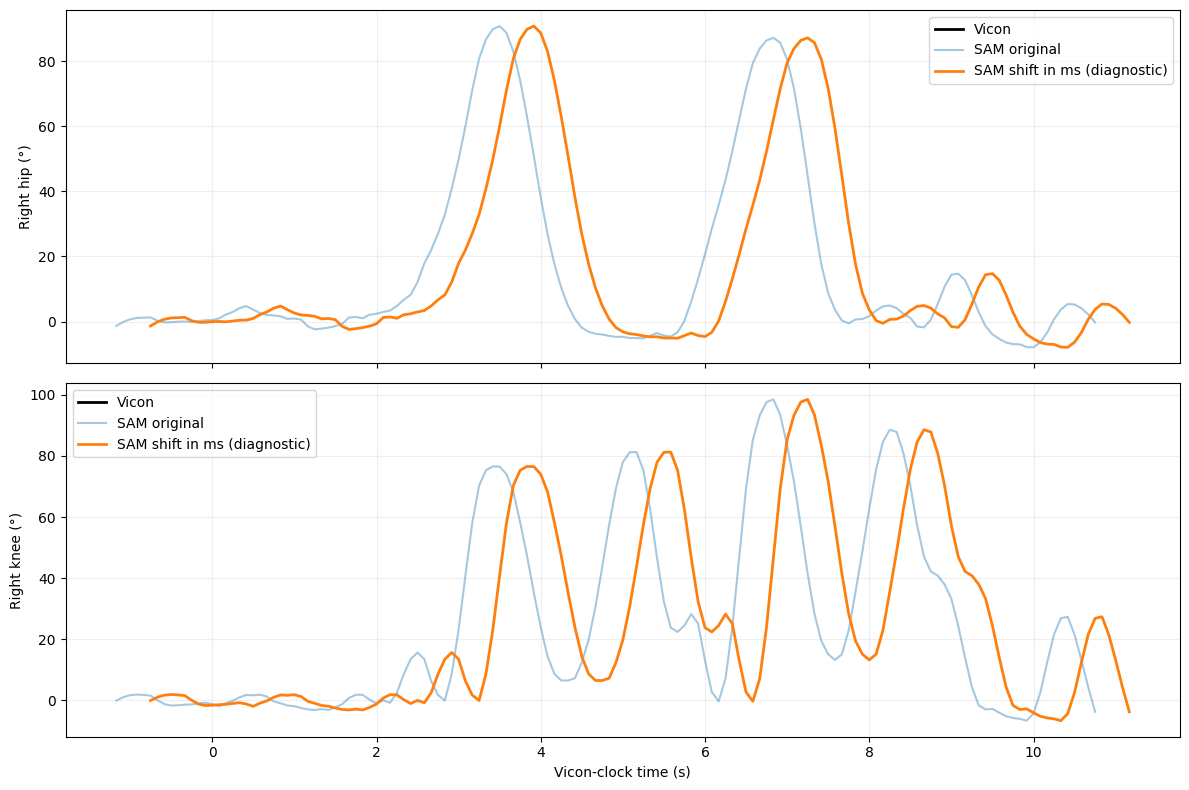

In [9]:
t = df["time_ms_aligned"].to_numpy(dtype=float) / 1000


DIAGNOSTIC_SHIFT_S = diagnostics["diagnostic_lag_ms"].iloc[1] / 1000  # Convert milliseconds to seconds
print(f"Diagnostic lag (knee, geometric): {DIAGNOSTIC_SHIFT_S * 1000:.1f} ms")

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

for ax, joint in zip(axes, ["hip", "knee"]):
    v = df[f"vicon_{joint}_flex"].to_numpy(dtype=float)
    s = df[f"r_{joint}_flex_geo"].to_numpy(dtype=float)

    # Neutral-reference each trajectory to initial standing
    static = t <= t[0] + 1.0

    v = v - np.nanmedian(v[static])
    s = s - np.nanmedian(s[static])

    ax.plot(t, v, color="black", lw=2, label="Vicon")

    ax.plot(
        t, s,
        color="tab:blue",
        alpha=0.4,
        label="SAM original"
    )

    ax.plot(
        t + DIAGNOSTIC_SHIFT_S, s,
        color="tab:orange",
        lw=2,
        label="SAM shift in ms (diagnostic)"
    )

    ax.set_ylabel(f"Right {joint} (°)")
    ax.legend()
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Vicon-clock time (s)")
plt.tight_layout()
plt.show()

In [10]:
# --------------------------------------------------
# Quantify RMSE improvement with diagnostic shift in ms

STATIC_MS = 1000.0

t = df["time_ms_aligned"].to_numpy(dtype=float)

results = []

for joint in ("hip", "knee", "ankle"):
    v = df[f"vicon_{joint}_flex"].to_numpy(dtype=float)
    s = df[f"r_{joint}_flex_geo"].to_numpy(dtype=float)

    valid = np.isfinite(t) & np.isfinite(v) & np.isfinite(s)

    tv, vv, ss = t[valid], v[valid], s[valid]

    static = tv <= tv[0] + STATIC_MS

    vv = vv - np.median(vv[static])
    ss = ss - np.median(ss[static])

    rmse_original = np.sqrt(np.mean((ss - vv) ** 2))

    # SAM(t) plotted at t + SHIFT_MS, evaluated on Vicon timestamps
    sam_shifted = np.interp(
        tv - DIAGNOSTIC_SHIFT_S * 1000,  # Convert seconds to milliseconds
        tv,
        ss,
        left=np.nan,
        right=np.nan
    )

    overlap = np.isfinite(sam_shifted)

    # Fair comparison: calculate both RMSEs over identical overlap
    rmse_before = np.sqrt(
        np.mean((ss[overlap] - vv[overlap]) ** 2)
    )
    rmse_after = np.sqrt(
        np.mean((sam_shifted[overlap] - vv[overlap]) ** 2)
    )

    results.append({
        "joint": joint,
        "rmse_original_deg": rmse_original,
        "rmse_before_same_overlap_deg": rmse_before,
        "rmse_after_333ms_deg": rmse_after,
        "improvement_pct": 100 * (
            rmse_before - rmse_after
        ) / rmse_before
    })

display(pd.DataFrame(results).round(2))

,joint,rmse_original_deg,rmse_before_same_overlap_deg,rmse_after_333ms_deg,improvement_pct
0,hip,45.91,47.01,46.80,0.44
1,knee,46.67,47.79,47.06,1.52
2,ankle,12.90,13.21,12.60,4.60


In [11]:
# --------------------------------------------------
# Configuration - diagnostic shift and static window
# --------------------------------------------------

METRICS_PATH = out_dir / "validation_metrics.csv"

t = df["time_ms_aligned"].to_numpy(dtype=float)

# --------------------------------------------------
# Extended validation metrics
# --------------------------------------------------
extended_rows = []

for joint in ("hip", "knee", "ankle"):
    for method in ("geo", "euler"):

        vicon_col = f"vicon_{joint}_flex"
        sam_col = f"r_{joint}_flex_{method}"

        if vicon_col not in df or sam_col not in df:
            continue

        v = df[vicon_col].to_numpy(dtype=float)
        s = df[sam_col].to_numpy(dtype=float)

        valid = np.isfinite(t) & np.isfinite(v) & np.isfinite(s)

        tv, vv, ss = t[valid], v[valid], s[valid]

        if len(tv) < 5:
            continue

        # Static / neutral reference
        static = tv <= tv[0] + STATIC_MS

        v0 = np.median(vv[static])
        s0 = np.median(ss[static])

        vn = vv - v0
        sn = ss - s0

        # Diagnostic shifted SAM, interpolated to reference time
        shifted = np.interp(
            tv - DIAGNOSTIC_SHIFT_S * 1000,  # Convert seconds to milliseconds
            tv,
            sn,
            left=np.nan,
            right=np.nan
        )

        overlap = np.isfinite(shifted)

        if overlap.sum() < 3:
            continue

        def rmse(a, b):
            return np.sqrt(np.mean((a - b) ** 2))

        rmse_neutral = rmse(sn, vn)

        # Identical overlap for fair before/after comparison
        rmse_before = rmse(sn[overlap], vn[overlap])
        rmse_after = rmse(shifted[overlap], vn[overlap])

        extended_rows.append({
            "joint": joint,
            "method": method,
            "baseline_offset_deg": v0 - s0,
            "vicon_rom_deg": np.ptp(vv),
            "sam_rom_deg": np.ptp(ss),
            "rom_difference_deg": np.ptp(ss) - np.ptp(vv),
            "rmse_neutral_deg": rmse_neutral,
            "rmse_neutral_same_overlap_deg": rmse_before,
            "rmse_neutral_shifted_deg": rmse_after,
            "diagnostic_shift_ms": DIAGNOSTIC_SHIFT_S * 1000,
            "rmse_improvement_pct": (
                100 * (rmse_before - rmse_after) / rmse_before
                if rmse_before > 0 else np.nan
            ),
            "calibration_window_ms": STATIC_MS,
            "shift_status": "diagnostic_joint_derived_not_validated"
        })

extended = pd.DataFrame(extended_rows)

# --------------------------------------------------
# Merge with existing validation metrics
# --------------------------------------------------
metrics = pd.read_csv(METRICS_PATH)

# Safe to rerun without creating duplicate columns
new_columns = extended.columns.difference(["joint", "method"])
metrics = metrics.drop(
    columns=[c for c in new_columns if c in metrics.columns],
    errors="ignore"
)

metrics = metrics.merge(
    extended,
    on=["joint", "method"],
    how="left",
    validate="one_to_one"
)

# Save updated CSV
metrics.to_csv(METRICS_PATH, index=False)

display(metrics.round(2))

print(f"Updated: {METRICS_PATH}")

,subject,trial,camera,side,joint,method,reference_origin,sync_method,sync_shift_ms,n_samples,...,vicon_rom_deg,sam_rom_deg,rom_difference_deg,rmse_neutral_deg,rmse_neutral_same_overlap_deg,rmse_neutral_shifted_deg,diagnostic_shift_ms,rmse_improvement_pct,calibration_window_ms,shift_status
0,S9,lunge_01,cam2,right,hip,geo,embedded_preinterpolated_vicon_unverified,prealigned_upstream,NaN,129,...,103.68,98.68,-5.00,45.91,47.01,46.80,416.72,0.44,1000.0,diagnostic_joint_derived_not_validated
1,S9,lunge_01,cam2,right,hip,euler,embedded_preinterpolated_vicon_unverified,prealigned_upstream,NaN,129,...,103.68,94.30,-9.38,39.22,40.17,37.26,416.72,7.25,1000.0,diagnostic_joint_derived_not_validated
2,S9,lunge_01,cam2,right,knee,geo,embedded_preinterpolated_vicon_unverified,prealigned_upstream,NaN,129,...,94.09,105.17,11.07,46.67,47.79,47.06,416.72,1.52,1000.0,diagnostic_joint_derived_not_validated
3,S9,lunge_01,cam2,right,knee,euler,embedded_preinterpolated_vicon_unverified,prealigned_upstream,NaN,129,...,94.09,110.16,16.07,48.70,49.87,48.99,416.72,1.77,1000.0,diagnostic_joint_derived_not_validated
4,S9,lunge_01,cam2,right,ankle,geo,embedded_preinterpolated_vicon_unverified,prealigned_upstream,NaN,129,...,37.58,38.00,0.42,12.90,13.21,12.60,416.72,4.60,1000.0,diagnostic_joint_derived_not_validated
5,S9,lunge_01,cam2,right,ankle,euler,embedded_preinterpolated_vicon_unverified,prealigned_upstream,NaN,129,...,37.58,32.82,-4.76,13.54,13.86,13.85,416.72,0.13,1000.0,diagnostic_joint_derived_not_validated


Updated: /Users/thomasjohnson/markerless/markerless_sam/results/S9/lunge_01/cam2/validation_metrics.csv


### Scientific checks
The imported CSVs may already be filtered and interpolated. Do not shift again. Document anatomical signs/definitions, and separately report raw versus independently calibrated error. For real independent validation, use raw SAM `time_ms`, reviewed `sync.json`, and standalone Vicon `time_ms`/angle CSV. Aggregate inference across reps/trials/subjects rather than treating all samples as independent.